# K-Nearest Neighbours — tuning, evaluation and test on 4 targets
Targets: **Cath** (overall CAD), **LAD**, **LCX**, **RCA**. Input: `data/processed/cad_clean.csv` produced by notebook 01 (frozen 80/20 stratified split).

Workflow: baseline → complexity / depth sweeps → feature-count sweep → GridSearchCV → RandomizedSearchCV → CV-fold study → nested CV (paper-comparable protocol) → threshold tuning → **single** test evaluation → paper methods (single / OR-rule / stacked) → permutation importance → save.

All scaling, encoding, feature selection and SMOTE sit inside one `imblearn` `Pipeline`, so every CV fold is leak-free. LAD/LCX/RCA/Cath are never inputs, except as *out-of-fold* probabilities in the paper's stacked method.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict, validation_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
pd.set_option('display.width',220,'display.max_columns',60,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42; M='knn'
ROOT=Path('..').resolve(); OUT=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=RES/'figures'; MOD=ROOT/'models'
for p in (RES,FIG,MOD): p.mkdir(parents=True,exist_ok=True)

## 1. Load the cleaned data and rebuild the same split

In [2]:
df = pd.read_csv(OUT/'cad_clean.csv', keep_default_na=False)
TARGETS=['Cath','LAD','LCX','RCA']; AUDIT=['Cath_original','label_corrected','n_vessels']
FEATURES=[c for c in df.columns if c not in ['patient_idx','split']+TARGETS+AUDIT]
assert not set(FEATURES)&set(TARGETS+AUDIT)
tr=df[df.split=='train']; te=df[df.split=='test']
X_tr,X_te,X_all=tr[FEATURES],te[FEATURES],df[FEATURES]
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}; Y_all={t:df[t].values for t in TARGETS}
print(len(FEATURES),'features | train',X_tr.shape,'| test',X_te.shape)
pd.DataFrame({'train_pos_rate':[Y_tr[t].mean() for t in TARGETS],'test_pos_rate':[Y_te[t].mean() for t in TARGETS]},index=TARGETS).round(3)

62 features | train (242, 62) | test (61, 62)


,train_pos_rate,test_pos_rate
Cath,0.715,0.721
LAD,0.583,0.590
LCX,0.388,0.410
RCA,0.376,0.377


## 2. Preprocessing definition (identical to notebook 01)

In [3]:
num_cols=['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
skew_cols=['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']
scale_cols=[c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols=['VHD','Function Class','Region RWMA']; nominal_cols=['BBB','CP_type','age_group']
binary_cols=[c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
def build_preprocessor():
    return ColumnTransformer([
        ('skew',Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]),skew_cols),
        ('num',StandardScaler(),scale_cols),
        ('ord',Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]),ordinal_cols),
        ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),nominal_cols),
        ('bin','passthrough',binary_cols)],verbose_feature_names_out=False)
# the explicit fit / fit_transform / transform sequence on this split
_p=build_preprocessor(); _a=_p.fit_transform(X_tr); _b=_p.transform(X_te)
print('fit_transform(train):',_a.shape,'| transform(test):',_b.shape)

fit_transform(train): (242, 70) | transform(test): (61, 70)


## 3. Pipeline factory, CV schemes, metric helpers

In [4]:
def make_pipe(clf):
    # prep -> univariate feature selection (k tunable, 'all' = off) -> sampler (tunable: passthrough | SMOTE) -> classifier
    return ImbPipeline([('prep',build_preprocessor()),('fs',SelectKBest(f_classif,k='all')),('sampler','passthrough'),('clf',clf)])
def new_clf(): return KNeighborsClassifier()
cv5  = StratifiedKFold(5,shuffle=True,random_state=SEED)
cv52 = RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=SEED)
SCORING={'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1','recall':'recall'}
spw={t:float((Y_tr[t]==0).sum()/(Y_tr[t]==1).sum()) for t in TARGETS}      # neg/pos ratio for scale_pos_weight
print({k:round(v,2) for k,v in spw.items()})

{'Cath': 0.4, 'LAD': 0.72, 'LCX': 1.57, 'RCA': 1.66}


In [5]:
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if tp+fn else np.nan; spec=tn/(tn+fp) if tn+fp else np.nan
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(sens+spec)/2,sensitivity=sens,specificity=spec,
                precision=precision_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),roc_auc=roc_auc_score(y,p),
                pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p),TP=tp,FP=fp,TN=tn,FN=fn)
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])       # highest threshold reaching sensitivity s (max specificity)
def boot_ci(y,p,thr,B=1000,seed=SEED):
    rng=np.random.default_rng(seed); a,b=[],[]
    for _ in range(B):
        i=rng.integers(0,len(y),len(y))
        if len(set(y[i]))<2: continue
        a.append(roc_auc_score(y[i],p[i])); b.append(accuracy_score(y[i],(p[i]>=thr).astype(int)))
    return np.percentile(a,[2.5,97.5]),np.percentile(b,[2.5,97.5])

## 4. Baselines: Dummy vs default model (5-fold × 2 repeats, train only)

In [6]:
def cv_row(est,t,cv=cv52):
    r=cross_validate(est,X_tr,Y_tr[t],cv=cv,scoring=SCORING,n_jobs=-1)
    return {k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}
rows=[]
for t in TARGETS:
    rows.append({'target':t,'model':'Dummy',**cv_row(make_pipe(DummyClassifier(strategy='prior')),t)})
    rows.append({'target':t,'model':'default '+M,**cv_row(make_pipe(new_clf()),t)})
baseline=pd.DataFrame(rows).set_index(['target','model']).round(3); baseline

roc_auc  average_precision  balanced_accuracy     f1  recall
target model                                                                    
Cath   Dummy          0.500              0.715              0.500  0.834   1.000
       default knn    0.842              0.908              0.680  0.857   0.913
LAD    Dummy          0.500              0.583              0.500  0.736   1.000
       default knn    0.759              0.785              0.693  0.750   0.770
LCX    Dummy          0.500              0.388              0.500  0.000   0.000
       default knn    0.639              0.496              0.570  0.427   0.373
RCA    Dummy          0.500              0.376              0.500  0.000   0.000
       default knn    0.604              0.467              0.573  0.423   0.374

## 5. Complexity / depth sweeps (train vs CV ROC-AUC)

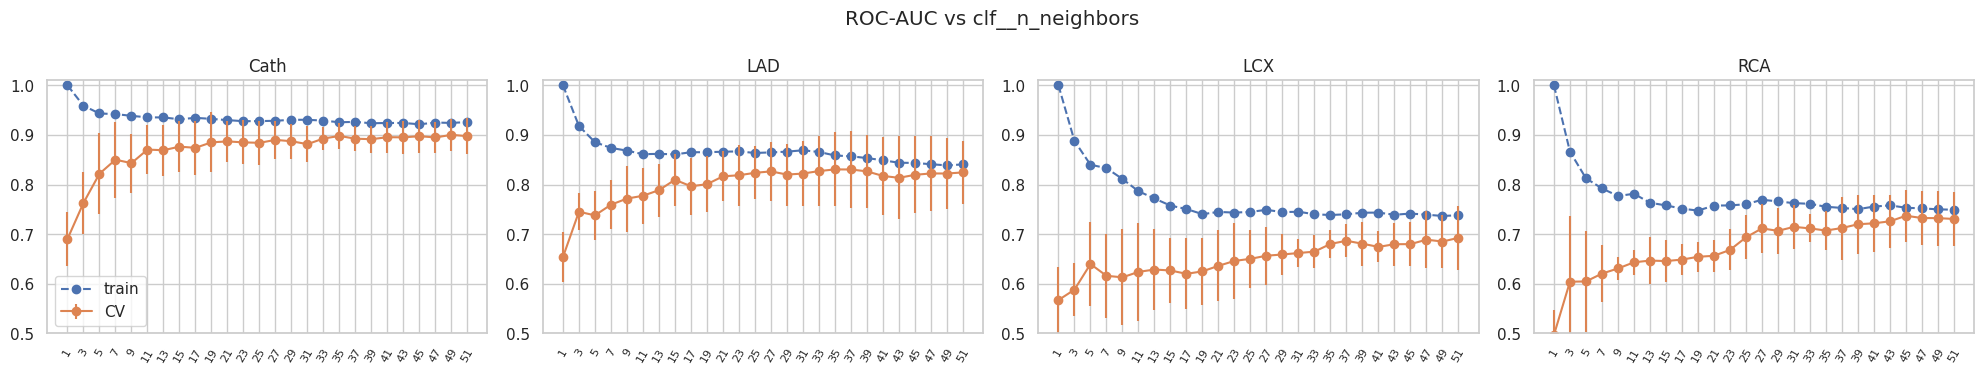

In [7]:
def sweep(param,values,title,fname):
    fig,axes=plt.subplots(1,4,figsize=(20,3.8)); out={}
    for ax,t in zip(axes,TARGETS):
        tr_s,cv_s=validation_curve(make_pipe(new_clf()),X_tr,Y_tr[t],param_name=param,param_range=values,cv=cv5,scoring='roc_auc',n_jobs=-1)
        xs=np.arange(len(values)); out[t]=pd.DataFrame({'value':[str(v) for v in values],'train_auc':tr_s.mean(1),'cv_auc':cv_s.mean(1),'cv_std':cv_s.std(1)})
        ax.plot(xs,tr_s.mean(1),'o--',label='train'); ax.errorbar(xs,cv_s.mean(1),cv_s.std(1),fmt='o-',label='CV')
        ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in values],rotation=60,fontsize=8); ax.set_title(f'{t}'); ax.set_ylim(0.5,1.01)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/f'knn_{fname}.png',dpi=110); plt.show(); return out
p1,v1=('clf__n_neighbors', list(range(1,52,2)))
sw1=sweep(p1,v1,f'ROC-AUC vs {p1}','sweep1')

In [8]:
pd.concat({t:sw1[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
1         1.000  0.690     1.000  0.654     1.000  0.567     1.000  0.497
3         0.959  0.763     0.918  0.745     0.888  0.588     0.866  0.604
5         0.943  0.822     0.885  0.738     0.840  0.640     0.813  0.605
7         0.942  0.850     0.874  0.759     0.833  0.616     0.792  0.621
9         0.938  0.843     0.868  0.772     0.811  0.613     0.777  0.631
11        0.935  0.870     0.861  0.777     0.787  0.624     0.781  0.643
13        0.935  0.869     0.862  0.789     0.772  0.629     0.763  0.647
15        0.932  0.876     0.861  0.810     0.758  0.627     0.758  0.646
17        0.934  0.874     0.865  0.797     0.751  0.620     0.751  0.649
19        0.932  0.885     0.865  0.801     0.740  0.625     0.748  0.654
21        0.930  0.887     0.866  0.817     0.745  0.636     0.758  0.657
23        0.928  0.885     0.867  0.819     0.744  0.646     0.758  0.668
25        0.928  0.884     0.864  0.824     0.745  0.650     0.760  0.694
27        0.929  0.890     0.865  0.827     0.749  0.657     0.769  0.712
29        0.930  0.887     0.866  0.820     0.744  0.659     0.766  0.707
31        0.931  0.881     0.869  0.822     0.745  0.662     0.763  0.715
33        0.929  0.893     0.866  0.827     0.740  0.665     0.761  0.712
35        0.926  0.898     0.859  0.831     0.739  0.680     0.755  0.707
37        0.926  0.892     0.857  0.830     0.740  0.687     0.753  0.712
39        0.923  0.891     0.853  0.827     0.743  0.681     0.750  0.720
41        0.924  0.895     0.849  0.817     0.744  0.674     0.756  0.722
43        0.924  0.895     0.844  0.814     0.739  0.680     0.758  0.726
45        0.921  0.897     0.844  0.820     0.742  0.680     0.753  0.737
47        0.925  0.895     0.841  0.822     0.739  0.689     0.752  0.733
49        0.924  0.900     0.839  0.822     0.737  0.685     0.750  0.732
51        0.926  0.898     0.841  0.824     0.738  0.693     0.749  0.731

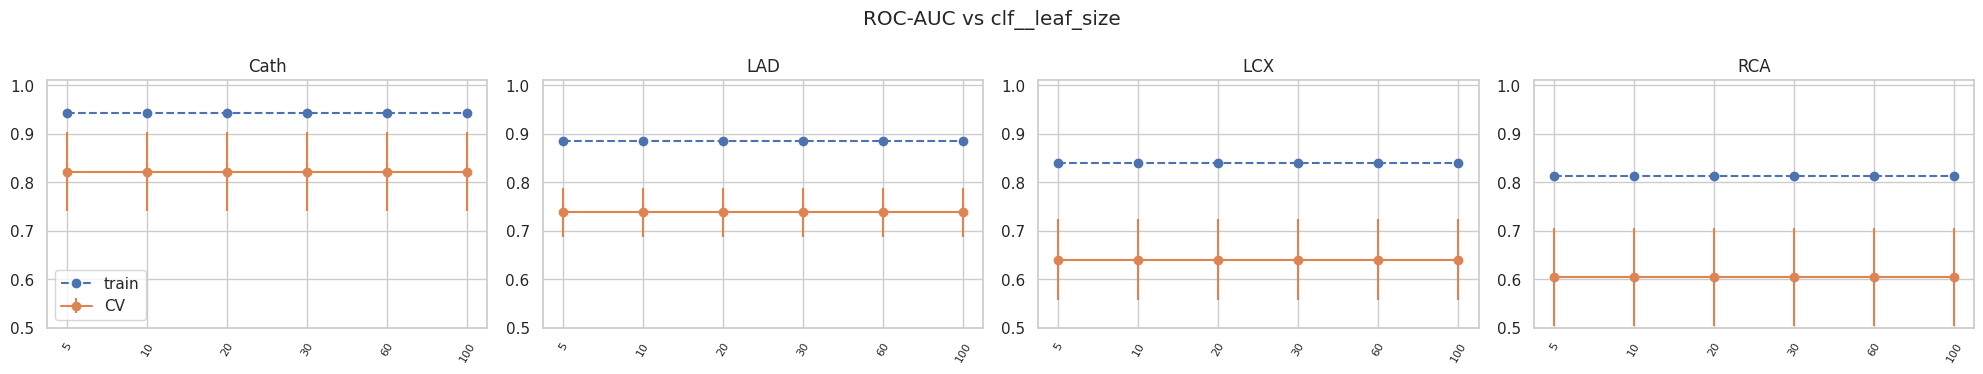

In [9]:
p2,v2=('clf__leaf_size', [5,10,20,30,60,100])
sw2=sweep(p2,v2,f'ROC-AUC vs {p2}','sweep2')

In [10]:
pd.concat({t:sw2[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605
10        0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605
20        0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605
30        0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605
60        0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605
100       0.943  0.822     0.885  0.738      0.84   0.64     0.813  0.605

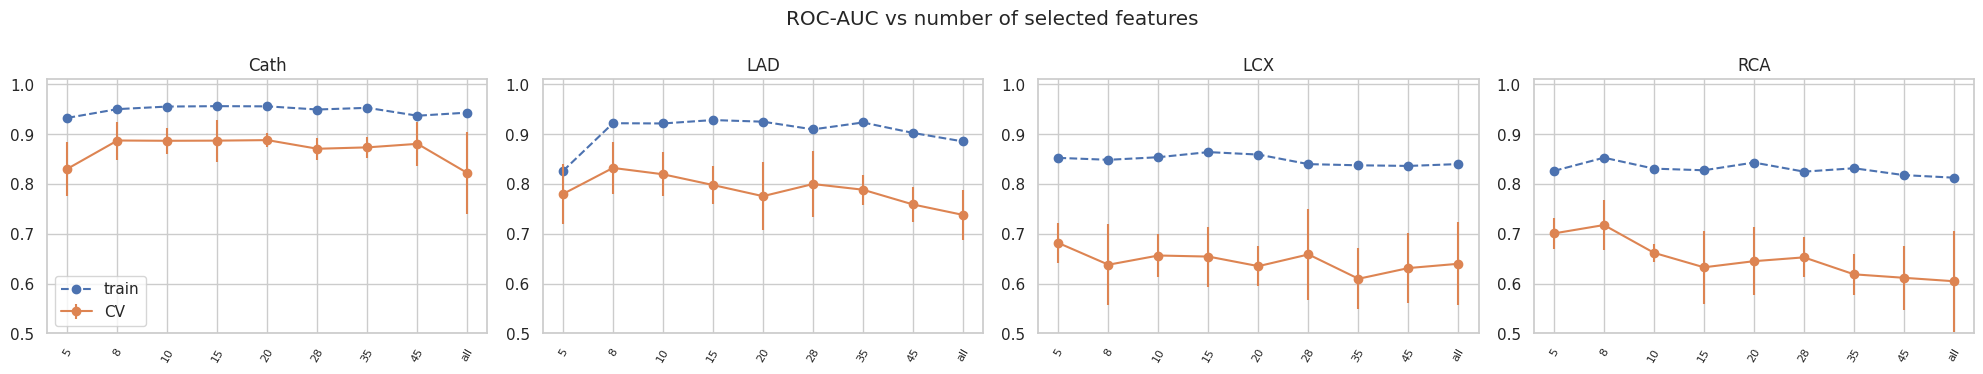

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.933  0.831     0.826  0.780     0.852  0.682     0.826  0.701
8         0.950  0.887     0.922  0.832     0.849  0.638     0.853  0.718
10        0.955  0.887     0.921  0.819     0.854  0.656     0.831  0.662
15        0.956  0.887     0.928  0.798     0.864  0.654     0.827  0.633
20        0.956  0.888     0.925  0.776     0.859  0.635     0.843  0.645
28        0.949  0.871     0.910  0.800     0.840  0.659     0.825  0.653
35        0.953  0.873     0.923  0.788     0.837  0.610     0.832  0.619
45        0.937  0.881     0.902  0.759     0.836  0.631     0.818  0.612
all       0.943  0.822     0.885  0.738     0.840  0.640     0.813  0.605

In [11]:
# number of selected features (SelectKBest inside the pipeline)
ks=[5,8,10,15,20,28,35,45,'all']
sw3=sweep('fs__k',ks,'ROC-AUC vs number of selected features','sweep_k')
pd.concat({t:sw3[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

## 6. GridSearchCV (focused grid, 5×2 repeated CV, 5 metrics, refit on ROC-AUC)

In [12]:
def param_grid(spw):
    return {'fs__k':[10,15,20,28,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__n_neighbors':list(range(3,40,2)),'clf__weights':['uniform','distance'],'clf__p':[1,2]}
def param_space(spw):
    return {'fs__k':[5,8,10,12,15,20,28,35,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__n_neighbors':randint(1,60),
            'clf__weights':['uniform','distance'],'clf__metric':['euclidean','manhattan','chebyshev','cosine'],'clf__leaf_size':randint(10,60)}
for t in TARGETS:
    g=param_grid(spw[t]); size=int(np.sum([np.prod([len(v) for v in d.values()]) for d in (g if isinstance(g,list) else [g])]))
    print(t,'grid combinations:',size,'-> fits:',size*10)

Cath grid combinations: 760 -> fits: 7600
LAD grid combinations: 760 -> fits: 7600
LCX grid combinations: 760 -> fits: 7600
RCA grid combinations: 760 -> fits: 7600


In [13]:
searches={t:{} for t in TARGETS}
for t in TARGETS:
    t0=time.time()
    gs=GridSearchCV(make_pipe(new_clf()),param_grid(spw[t]),scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,verbose=0)
    gs.fit(X_tr,Y_tr[t]); searches[t]['grid']=gs
    pd.DataFrame(gs.cv_results_).to_csv(RES/f'{M}_cv_grid_{t}.csv',index=False)
    print(f'{t}: best CV AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s, {len(gs.cv_results_["params"])} combos)')

Cath: best CV AUC=0.9331  (16s, 760 combos)


LAD: best CV AUC=0.8621  (16s, 760 combos)


LCX: best CV AUC=0.7172  (17s, 760 combos)


RCA: best CV AUC=0.7367  (16s, 760 combos)


## 7. RandomizedSearchCV (wide space, many more combinations)

In [14]:
N_ITER=250
for t in TARGETS:
    t0=time.time()
    rs=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=N_ITER,scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,random_state=SEED,verbose=0)
    rs.fit(X_tr,Y_tr[t]); searches[t]['random']=rs
    pd.DataFrame(rs.cv_results_).to_csv(RES/f'{M}_cv_random_{t}.csv',index=False)
    print(f'{t}: best CV AUC={rs.best_score_:.4f}  ({time.time()-t0:.0f}s)')

Cath: best CV AUC=0.9321  (6s)


LAD: best CV AUC=0.8603  (6s)


LCX: best CV AUC=0.7267  (6s)


RCA: best CV AUC=0.7444  (6s)


## 8. Pick the best configuration per target

In [15]:
best_est,rows={},[]
for t in TARGETS:
    g,r=searches[t]['grid'],searches[t]['random']
    win,name=(g,'grid') if g.best_score_>=r.best_score_ else (r,'random')
    best_est[t]=win.best_estimator_; i=win.best_index_; cr=win.cv_results_
    rows.append({'target':t,'winner':name,'cv_roc_auc':cr['mean_test_roc_auc'][i],'cv_pr_auc':cr['mean_test_average_precision'][i],
                 'cv_bal_acc':cr['mean_test_balanced_accuracy'][i],'cv_f1':cr['mean_test_f1'][i],'cv_recall':cr['mean_test_recall'][i],
                 'grid_auc':g.best_score_,'random_auc':r.best_score_})
best_tbl=pd.DataFrame(rows).set_index('target').round(4); best_tbl

,winner,cv_roc_auc,cv_pr_auc,cv_bal_acc,cv_f1,cv_recall,grid_auc,random_auc
target,,,,,,,,
Cath,grid,0.9331,0.9753,0.8059,0.8974,0.9101,0.9331,0.9321
LAD,grid,0.8621,0.8793,0.7804,0.8225,0.8369,0.8621,0.8603
LCX,random,0.7267,0.6140,0.5754,0.3242,0.2181,0.7172,0.7267
RCA,random,0.7444,0.6070,0.5592,0.3041,0.2082,0.7367,0.7444


In [16]:
best_params=pd.DataFrame({t:{k:str(v) for k,v in best_est[t].get_params().items() if k.startswith(('clf__','fs__k','sampler'))
                                 and not isinstance(v,(dict,)) and k not in ('sampler__random_state',)} for t in TARGETS}); best_params

,Cath,LAD,LCX,RCA
sampler,passthrough,passthrough,passthrough,passthrough
fs__k,28,10,all,35
clf__algorithm,auto,auto,auto,auto
clf__leaf_size,30,30,55,45
clf__metric,minkowski,minkowski,cosine,manhattan
clf__metric_params,None,None,None,None
clf__n_jobs,None,None,None,None
clf__n_neighbors,27,11,54,49
clf__p,1,1,2,2
clf__weights,distance,uniform,uniform,uniform


In [17]:
# top-5 combinations per target (from both searches)
for t in TARGETS:
    parts=[]
    for nm in ('grid','random'):
        d=pd.DataFrame(searches[t][nm].cv_results_); d['search']=nm; parts.append(d)
    d=pd.concat(parts).sort_values('mean_test_roc_auc',ascending=False).head(5)
    print('==',t); print(d[['search','mean_test_roc_auc','std_test_roc_auc','mean_test_balanced_accuracy','mean_test_recall','params']].to_string(index=False,max_colwidth=160))

== Cath
search  mean_test_roc_auc  std_test_roc_auc  mean_test_balanced_accuracy  mean_test_recall                                                                                                   params
  grid           0.933070          0.024000                     0.805866          0.910084 {'clf__n_neighbors': 27, 'clf__p': 1, 'clf__weights': 'distance', 'fs__k': 28, 'sampler': 'passthrough'}
  grid           0.932832          0.020666                     0.807020          0.912941 {'clf__n_neighbors': 35, 'clf__p': 1, 'clf__weights': 'distance', 'fs__k': 28, 'sampler': 'passthrough'}
  grid           0.932673          0.025358                     0.821099          0.918571 {'clf__n_neighbors': 19, 'clf__p': 1, 'clf__weights': 'distance', 'fs__k': 28, 'sampler': 'passthrough'}
  grid           0.932648          0.024405                     0.807211          0.912773 {'clf__n_neighbors': 39, 'clf__p': 1, 'clf__weights': 'distance', 'fs__k': 28, 'sampler': 'passthrough'}
  grid      

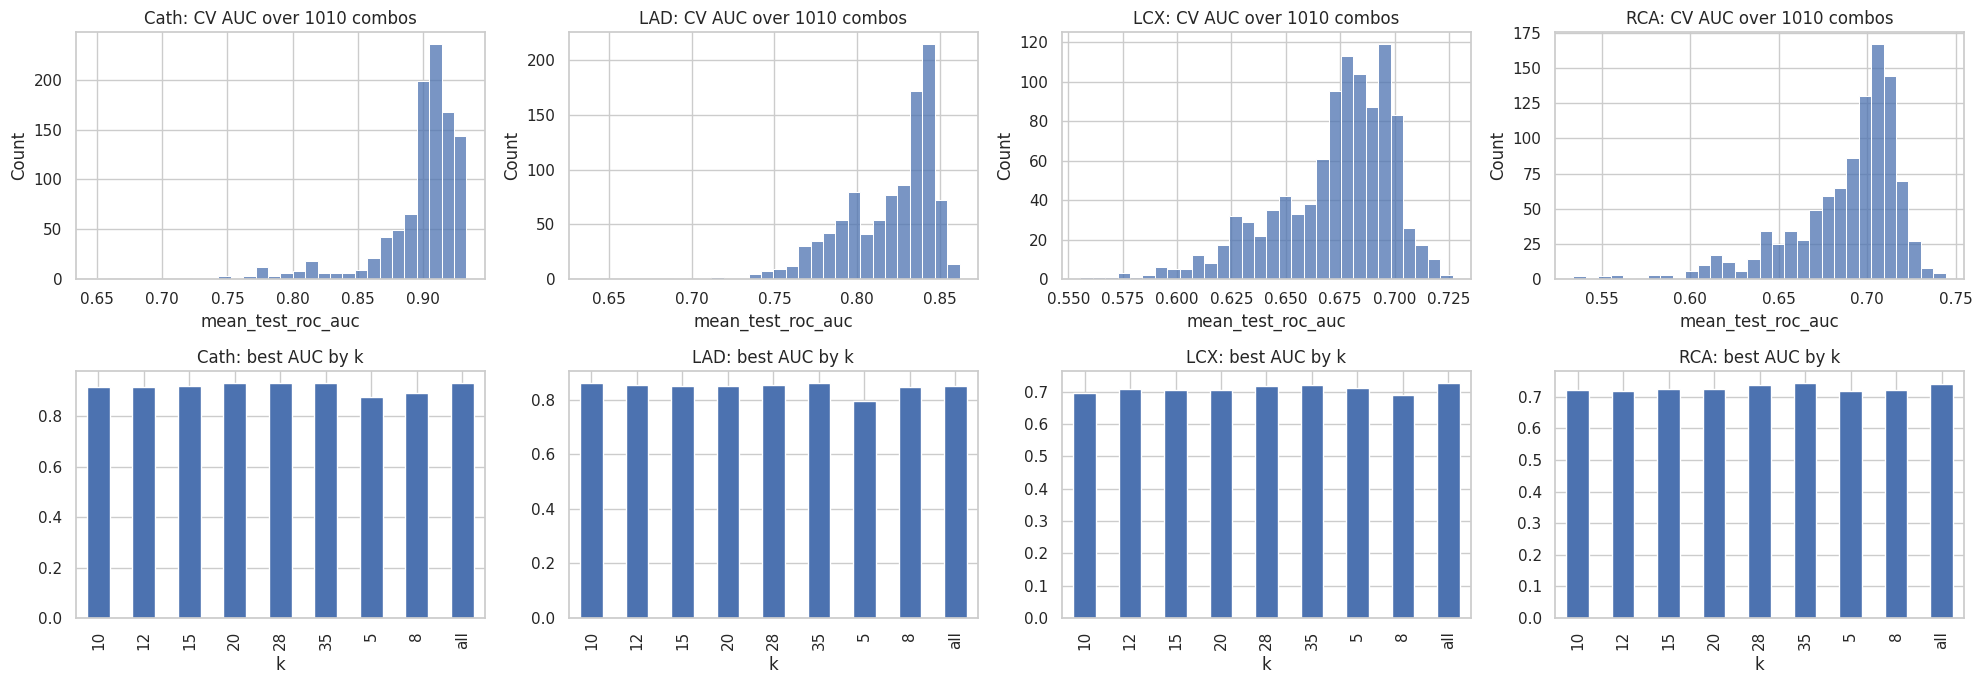

In [18]:
# distribution of CV AUC over all tried combinations + effect of depth if it was tuned
fig,axes=plt.subplots(2,4,figsize=(20,7))
for j,t in enumerate(TARGETS):
    d=pd.concat([pd.DataFrame(searches[t][n_].cv_results_) for n_ in ('grid','random')])
    sns.histplot(d.mean_test_roc_auc,bins=30,ax=axes[0,j]); axes[0,j].set_title(f'{t}: CV AUC over {len(d)} combos')
    col=[c for c in d.columns if c.endswith('max_depth')]
    if col:
        dd=d.assign(depth=d[col[0]].astype(str)).groupby('depth').mean_test_roc_auc.agg(['mean','max'])
        dd=dd.loc[sorted(dd.index,key=lambda s:(s=='None',float(s) if s not in ('None',) else 99))]
        dd.plot(ax=axes[1,j],marker='o'); axes[1,j].set_title(f'{t}: AUC by max_depth')
    else:
        d.assign(k=d['param_fs__k'].astype(str)).groupby('k').mean_test_roc_auc.max().plot.bar(ax=axes[1,j]); axes[1,j].set_title(f'{t}: best AUC by k')
plt.tight_layout(); plt.savefig(FIG/f'{M}_search_overview.png',dpi=110); plt.show()

## 9. Effect of the number of CV folds (best configuration, train only)

In [19]:
schemes={'3-fold':StratifiedKFold(3,shuffle=True,random_state=SEED),'5-fold':StratifiedKFold(5,shuffle=True,random_state=SEED),
         '7-fold':StratifiedKFold(7,shuffle=True,random_state=SEED),'10-fold':StratifiedKFold(10,shuffle=True,random_state=SEED),
         '5x3 repeated':RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED),'10x3 repeated':RepeatedStratifiedKFold(n_splits=10,n_repeats=3,random_state=SEED)}
rows=[]
for t in TARGETS:
    for nm,cv in schemes.items():
        s=cross_validate(clone(best_est[t]),X_tr,Y_tr[t],cv=cv,scoring={'auc':'roc_auc','acc':'accuracy','bal':'balanced_accuracy'},n_jobs=-1)
        rows.append({'target':t,'cv':nm,'auc_mean':s['test_auc'].mean(),'auc_std':s['test_auc'].std(),'acc_mean':s['test_acc'].mean(),'bal_acc_mean':s['test_bal'].mean()})
fold_tbl=pd.DataFrame(rows); fold_tbl.to_csv(RES/f'{M}_cv_fold_study.csv',index=False)
fold_tbl.pivot(index='cv',columns='target',values='auc_mean').loc[list(schemes)].round(4)

target,Cath,LAD,LCX,RCA
cv,,,,
3-fold,0.9301,0.8490,0.6900,0.7463
5-fold,0.9348,0.8621,0.7220,0.7437
7-fold,0.9304,0.8702,0.7211,0.7301
10-fold,0.9470,0.8566,0.7285,0.7363
5x3 repeated,0.9292,0.8648,0.7228,0.7457
10x3 repeated,0.9320,0.8609,0.7243,0.7468


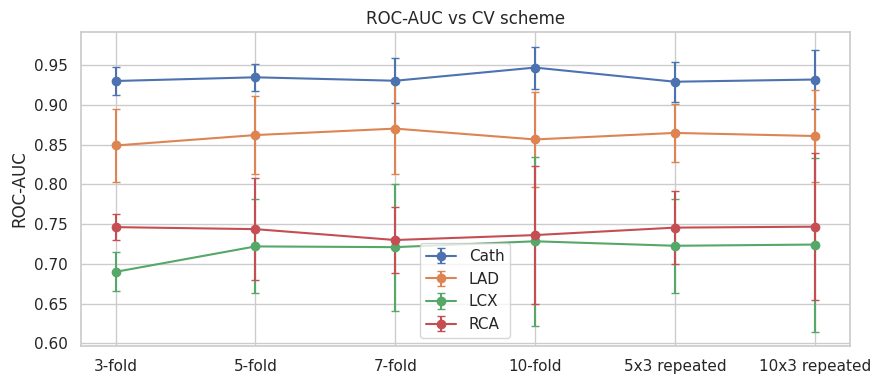

In [20]:
fig,ax=plt.subplots(figsize=(9,4))
for t in TARGETS:
    d=fold_tbl[fold_tbl.target==t]; ax.errorbar(range(len(d)),d.auc_mean,d.auc_std,marker='o',label=t,capsize=3)
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(list(schemes)); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('ROC-AUC vs CV scheme'); plt.tight_layout(); plt.show()

## 10. Nested CV on all 303 patients (paper-comparable protocol)
The paper reports 10-fold CV on all data. Here every outer fold tunes hyper-parameters (feature count, sampler, model parameters) on its own training part only, so the numbers are not tuned on the fold that scores them. Threshold = 0.5.

In [21]:
spec_scorer=make_scorer(recall_score,pos_label=0)
NEST_SCORING={'accuracy':'accuracy','balanced_acc':'balanced_accuracy','sensitivity':'recall','specificity':spec_scorer,'precision':'precision','f1':'f1','roc_auc':'roc_auc'}
outer=StratifiedKFold(10,shuffle=True,random_state=SEED); nested_rows=[]
for t in TARGETS:
    t0=time.time()
    inner=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=30,scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1,random_state=SEED)
    r=cross_validate(inner,X_all,Y_all[t],cv=outer,scoring=NEST_SCORING,n_jobs=-1)
    row={'target':t}; row.update({k.replace('test_',''):r[k].mean() for k in r if k.startswith('test_')}); row.update({k.replace('test_','')+'_std':r[k].std() for k in r if k.startswith('test_')})
    nested_rows.append(row); print(t,f"acc={row['accuracy']:.3f} sens={row['sensitivity']:.3f} spec={row['specificity']:.3f} auc={row['roc_auc']:.3f} ({time.time()-t0:.0f}s)")
nested=pd.DataFrame(nested_rows).set_index('target'); nested.to_csv(RES/f'{M}_nested_cv.csv'); nested[[c for c in nested if not c.endswith('_std')]].round(4)

Cath acc=0.819 sens=0.807 spec=0.853 auc=0.920 (2s)


LAD acc=0.736 sens=0.758 spec=0.708 auc=0.838 (2s)


LCX acc=0.648 sens=0.698 spec=0.615 auc=0.724 (2s)


RCA acc=0.633 sens=0.613 spec=0.646 auc=0.711 (2s)


,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc
target,,,,,,,
Cath,0.8189,0.8297,0.8067,0.8528,0.9408,0.8635,0.9196
LAD,0.7363,0.7331,0.7578,0.7083,0.7904,0.7663,0.8385
LCX,0.6476,0.6567,0.6985,0.6149,0.5817,0.6095,0.7241
RCA,0.6334,0.6292,0.6129,0.6456,0.5345,0.5453,0.7114


## 11. Decision threshold from out-of-fold *train* probabilities

In [22]:
def oof_proba(est,X,y,seeds=(0,1,2)):
    P=np.zeros(len(y))
    for s in seeds: P+=cross_val_predict(clone(est),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=s),method='predict_proba',n_jobs=-1)[:,1]
    return P/len(seeds)
oof={t:oof_proba(best_est[t],X_tr,Y_tr[t]) for t in TARGETS}
THR={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],oof[t]),'sens>=0.95':thr_sens(Y_tr[t],oof[t],0.95)} for t in TARGETS}
pd.DataFrame(THR).T.round(3)

,default_0.5,youden,sens>=0.95
Cath,0.5,0.626,0.380
LAD,0.5,0.636,0.303
LCX,0.5,0.420,0.278
RCA,0.5,0.395,0.238


In [23]:
pd.DataFrame({(t,k):metrics_at(Y_tr[t],oof[t],v) for t in TARGETS for k,v in THR[t].items()}).T[['threshold','accuracy','sensitivity','specificity','roc_auc']].round(3)

threshold  accuracy  sensitivity  specificity  roc_auc
Cath default_0.5      0.500     0.860        0.919        0.710    0.924
     youden           0.626     0.864        0.867        0.855    0.924
     sens>=0.95       0.380     0.843        0.954        0.565    0.924
LAD  default_0.5      0.500     0.785        0.830        0.723    0.864
     youden           0.636     0.777        0.738        0.832    0.864
     sens>=0.95       0.303     0.777        0.965        0.515    0.864
LCX  default_0.5      0.500     0.653        0.245        0.912    0.717
     youden           0.420     0.690        0.691        0.689    0.717
     sens>=0.95       0.278     0.488        0.957        0.189    0.717
RCA  default_0.5      0.500     0.661        0.209        0.934    0.740
     youden           0.395     0.715        0.703        0.722    0.740
     sens>=0.95       0.238     0.558        0.956        0.318    0.740

## 12. Final evaluation on the held-out test set (touched once)

In [24]:
test_proba={}
for t in TARGETS:
    best_est[t].fit(X_tr,Y_tr[t]); test_proba[t]=best_est[t].predict_proba(X_te)[:,1]
rows=[]
for t in TARGETS:
    for k,thr in THR[t].items():
        m=metrics_at(Y_te[t],test_proba[t],thr); (alo,ahi),(clo,chi)=boot_ci(Y_te[t],test_proba[t],thr)
        rows.append({'target':t,'strategy':'direct','threshold_rule':k,**m,'auc_ci':f'[{alo:.3f},{ahi:.3f}]','acc_ci':f'[{clo:.3f},{chi:.3f}]'})
test_tbl=pd.DataFrame(rows); test_tbl.to_csv(RES/f'{M}_test_metrics_direct.csv',index=False)
test_tbl[['target','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier','auc_ci','acc_ci']].round(3)

,target,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,auc_ci,acc_ci
0,Cath,default_0.5,0.500,0.836,0.778,0.909,0.647,0.870,0.889,0.898,0.962,0.115,"[0.811,0.972]","[0.738,0.918]"
1,Cath,youden,0.626,0.836,0.814,0.864,0.765,0.905,0.884,0.898,0.962,0.115,"[0.811,0.972]","[0.738,0.918]"
2,Cath,sens>=0.95,0.380,0.770,0.642,0.932,0.353,0.788,0.854,0.898,0.962,0.115,"[0.811,0.972]","[0.656,0.869]"
3,LAD,default_0.5,0.500,0.705,0.701,0.722,0.680,0.765,0.743,0.779,0.826,0.192,"[0.657,0.890]","[0.574,0.820]"
4,LAD,youden,0.636,0.656,0.659,0.639,0.680,0.742,0.687,0.779,0.826,0.192,"[0.657,0.890]","[0.525,0.787]"
5,LAD,sens>=0.95,0.303,0.721,0.678,0.917,0.440,0.702,0.795,0.779,0.826,0.192,"[0.657,0.890]","[0.607,0.820]"
6,LCX,default_0.5,0.500,0.689,0.638,0.360,0.917,0.750,0.486,0.767,0.679,0.207,"[0.650,0.878]","[0.574,0.803]"
7,LCX,youden,0.420,0.738,0.729,0.680,0.778,0.680,0.680,0.767,0.679,0.207,"[0.650,0.878]","[0.623,0.836]"
8,LCX,sens>=0.95,0.278,0.525,0.591,0.960,0.222,0.462,0.623,0.767,0.679,0.207,"[0.650,0.878]","[0.393,0.639]"
9,RCA,default_0.5,0.500,0.705,0.626,0.304,0.947,0.778,0.438,0.673,0.625,0.210,"[0.535,0.807]","[0.590,0.803]"


In [25]:
# majority-class reference on the same test set
pd.DataFrame({t:{'majority-class accuracy':max(Y_te[t].mean(),1-Y_te[t].mean()),'model accuracy (youden)':test_tbl[(test_tbl.target==t)&(test_tbl.threshold_rule=='youden')].accuracy.iloc[0]} for t in TARGETS}).T.round(3)

,majority-class accuracy,model accuracy (youden)
Cath,0.721,0.836
LAD,0.590,0.656
LCX,0.590,0.738
RCA,0.623,0.590


## 13. Curves and confusion matrices

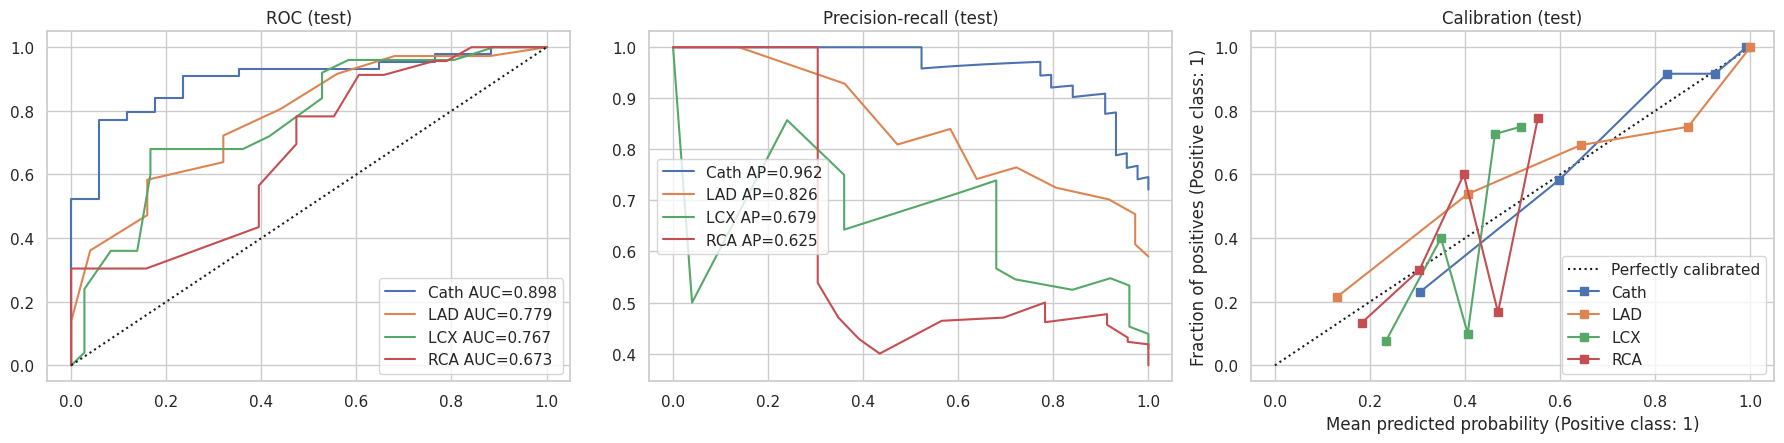

In [26]:
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
for t in TARGETS:
    f,s,_=roc_curve(Y_te[t],test_proba[t]); axes[0].plot(f,s,label=f'{t} AUC={roc_auc_score(Y_te[t],test_proba[t]):.3f}')
    p,r,_=precision_recall_curve(Y_te[t],test_proba[t]); axes[1].plot(r,p,label=f'{t} AP={average_precision_score(Y_te[t],test_proba[t]):.3f}')
    CalibrationDisplay.from_predictions(Y_te[t],test_proba[t],n_bins=5,strategy='quantile',ax=axes[2],name=t)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set_title('ROC (test)'); axes[1].set_title('Precision-recall (test)'); axes[2].set_title('Calibration (test)')
for a in axes[:2]: a.legend()
plt.tight_layout(); plt.savefig(FIG/f'{M}_curves.png',dpi=110); plt.show()

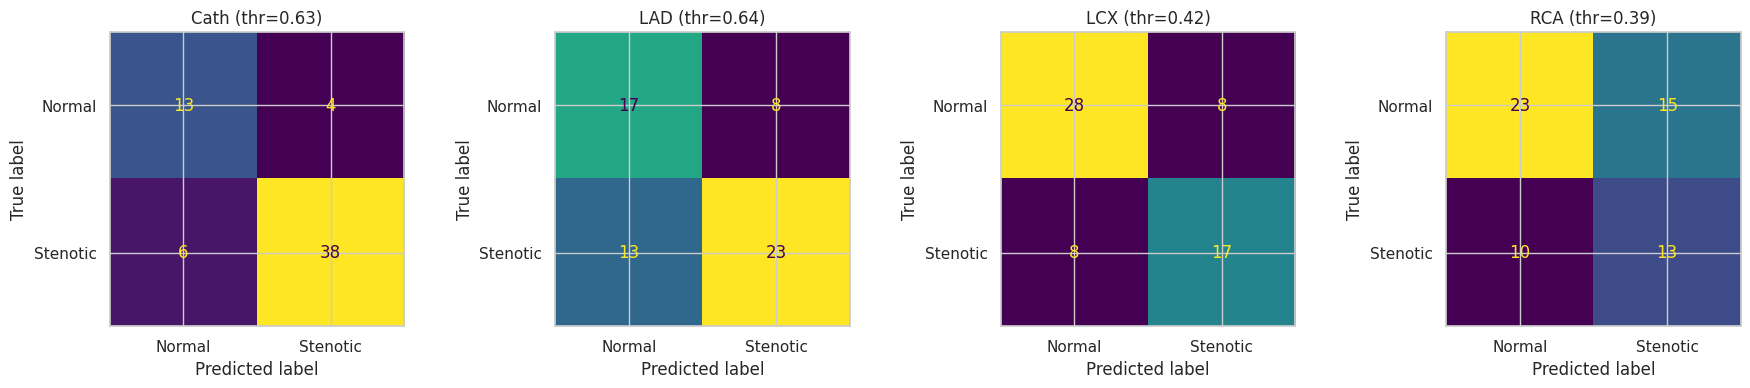

In [27]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,t in zip(axes,TARGETS):
    thr=THR[t]['youden']; ConfusionMatrixDisplay.from_predictions(Y_te[t],(test_proba[t]>=thr).astype(int),ax=ax,colorbar=False,display_labels=['Normal','Stenotic']); ax.set_title(f'{t} (thr={thr:.2f})')
plt.tight_layout(); plt.savefig(FIG/f'{M}_confusion.png',dpi=110); plt.show()

## 14. Paper methods on this model family
1. **Single classifier** – Cath model only (section 12).
2. **Three-classifier OR rule** – `CT = LAD ∨ LCX ∨ RCA` (Eq. 1 of the paper).
3. **Feature-engineering (stacked) method** – out-of-fold probabilities of the LAD/LCX/RCA/CAD models are appended to the clinical features and a final CAD classifier is trained on them. Train probabilities are out-of-fold, test probabilities come from models fitted on the full train set.

In [28]:
# 2) OR rule
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(test_proba[t]>=THR[t][rule]).astype(int)
    score=1-np.prod([1-test_proba[t] for t in ['LAD','LCX','RCA']],axis=0)               # P(at least one stenotic), independence assumption
    yh=pred; tn,fp,fn,tp=confusion_matrix(Y_te['Cath'],yh,labels=[0,1]).ravel()
    rows.append({'target':'Cath','strategy':'OR-rule','threshold_rule':rule,'accuracy':accuracy_score(Y_te['Cath'],yh),'balanced_acc':balanced_accuracy_score(Y_te['Cath'],yh),
                 'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'precision':precision_score(Y_te['Cath'],yh,zero_division=0),'f1':f1_score(Y_te['Cath'],yh),
                 'roc_auc':roc_auc_score(Y_te['Cath'],score),'pr_auc':average_precision_score(Y_te['Cath'],score),'brier':brier_score_loss(Y_te['Cath'],score),'TP':tp,'FP':fp,'TN':tn,'FN':fn})
or_tbl=pd.DataFrame(rows); or_tbl.round(3)

,target,strategy,threshold_rule,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,OR-rule,default_0.5,0.754,0.757,0.750,0.765,0.892,0.815,0.885,0.952,0.137,33,4,13,11
1,Cath,OR-rule,youden,0.787,0.762,0.818,0.706,0.878,0.847,0.885,0.952,0.137,36,5,12,8


In [29]:
# 3) stacked method
PCOLS=['p_LAD','p_LCX','p_RCA','p_CAD']
oof_tr={t:cross_val_predict(clone(best_est[t]),X_tr,Y_tr[t],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba',n_jobs=-1)[:,1] for t in TARGETS}
def augment(X,P):
    A=X.copy()
    for c,t in zip(PCOLS,['LAD','LCX','RCA','Cath']): A[c]=P[t]
    return A
Xa_tr=augment(X_tr,oof_tr); Xa_te=augment(X_te,test_proba)
def meta_pipe():
    p=clone(best_est['Cath']); p.set_params(prep=ColumnTransformer([('base',build_preprocessor(),FEATURES),('probs','passthrough',PCOLS)],verbose_feature_names_out=False))
    return p
mg=GridSearchCV(meta_pipe(),{'fs__k':[4,8,12,20,32,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)]},scoring='roc_auc',cv=cv52,n_jobs=-1).fit(Xa_tr,Y_tr['Cath'])
meta=mg.best_estimator_; print('stacked CV AUC:',round(mg.best_score_,4),'| params:',{k:v for k,v in mg.best_params_.items()})
oof_meta=oof_proba(meta,Xa_tr,Y_tr['Cath']); thr_meta={'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],oof_meta),'sens>=0.95':thr_sens(Y_tr['Cath'],oof_meta,0.95)}
meta.fit(Xa_tr,Y_tr['Cath']); p_meta=meta.predict_proba(Xa_te)[:,1]
st=pd.DataFrame([{'target':'Cath','strategy':'stacked (paper FE)','threshold_rule':k,**metrics_at(Y_te['Cath'],p_meta,v)} for k,v in thr_meta.items()]); st.round(3)

stacked CV AUC: 0.9333 | params: {'fs__k': 32, 'sampler': 'passthrough'}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,stacked (paper FE),default_0.5,0.500,0.869,0.819,0.932,0.706,0.891,0.911,0.898,0.961,0.113,41,5,12,3
1,Cath,stacked (paper FE),youden,0.563,0.852,0.826,0.886,0.765,0.907,0.897,0.898,0.961,0.113,39,4,13,5
2,Cath,stacked (paper FE),sens>=0.95,0.351,0.820,0.713,0.955,0.471,0.824,0.884,0.898,0.961,0.113,42,9,8,2


In [30]:
# compare the three strategies for CAD with the paper's SVM numbers (10-fold CV on 500 patients; ours: held-out test of 61)
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},
                    {'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
ours=pd.concat([test_tbl[test_tbl.target=='Cath'].assign(strategy=lambda d:'direct @'+d.threshold_rule),or_tbl.assign(strategy=lambda d:'OR-rule @'+d.threshold_rule),
                st.assign(strategy=lambda d:'stacked @'+d.threshold_rule)])[['strategy','accuracy','sensitivity','specificity','roc_auc']]
cmp_tbl=pd.concat([paper,ours.assign(strategy=lambda d:'OURS '+M+' '+d.strategy)]).set_index('strategy'); cmp_tbl.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
OURS knn direct @default_0.5,0.836,0.909,0.647,0.898
OURS knn direct @youden,0.836,0.864,0.765,0.898
OURS knn direct @sens>=0.95,0.770,0.932,0.353,0.898
OURS knn OR-rule @default_0.5,0.754,0.750,0.765,0.885
OURS knn OR-rule @youden,0.787,0.818,0.706,0.885
OURS knn stacked @default_0.5,0.869,0.932,0.706,0.898


In [31]:
all_rows=pd.concat([test_tbl,or_tbl,st]); all_rows.to_csv(RES/f'{M}_test_metrics.csv',index=False)
nested.loc[['Cath']].round(3).rename(index={'Cath':'OURS nested 10-fold CV (303 pts, thr 0.5)'})[['accuracy','sensitivity','specificity','roc_auc']]

,accuracy,sensitivity,specificity,roc_auc
target,,,,
"OURS nested 10-fold CV (303 pts, thr 0.5)",0.819,0.807,0.853,0.92


## 15. Permutation importance on the test set (raw features, per target)

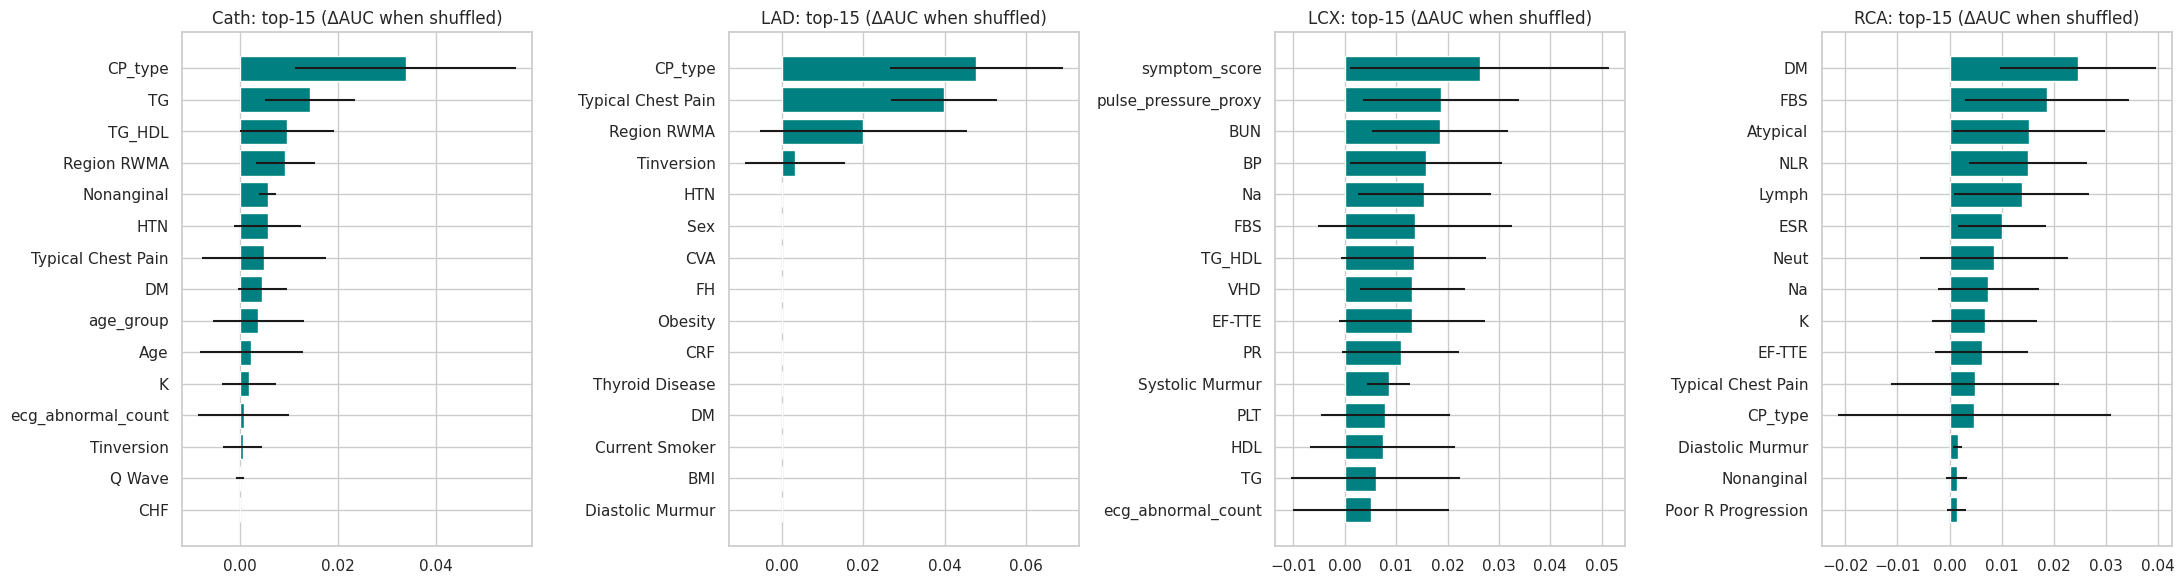

In [32]:
imp={}
for t in TARGETS:
    r=permutation_importance(best_est[t],X_te,Y_te[t],scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=-1)
    imp[t]=pd.DataFrame({'importance':r.importances_mean,'std':r.importances_std},index=FEATURES).sort_values('importance',ascending=False)
    imp[t].to_csv(RES/f'{M}_perm_importance_{t}.csv')
fig,axes=plt.subplots(1,4,figsize=(22,6))
for ax,t in zip(axes,TARGETS):
    d=imp[t].head(15)[::-1]; ax.barh(d.index,d.importance,xerr=d['std'],color='teal'); ax.set_title(f'{t}: top-15 (ΔAUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG/f'{M}_perm_importance.png',dpi=110); plt.show()

In [33]:
pd.concat({t:imp[t].head(10).importance.round(4).reset_index().rename(columns={'index':'feature'}) for t in TARGETS},axis=1)

Cath                            LAD                              LCX                  RCA           
              feature importance             feature importance               feature importance   feature importance
0             CP_type     0.0338             CP_type     0.0478         symptom_score     0.0263        DM     0.0246
1                  TG     0.0144  Typical Chest Pain     0.0399  pulse_pressure_proxy     0.0187       FBS     0.0187
2              TG_HDL     0.0097         Region RWMA     0.0200                   BUN     0.0186  Atypical     0.0153
3         Region RWMA     0.0093          Tinversion     0.0032                    BP     0.0159       NLR     0.0151
4          Nonanginal     0.0057                 HTN     0.0000                    Na     0.0155     Lymph     0.0138
5                 HTN     0.0057                 Sex     0.0000                   FBS     0.0136       ESR     0.0100
6  Typical Chest Pain     0.0050                 CVA     0.0000                TG_HDL     0.0134      Neut     0.0084
7                  DM     0.0046                  FH     0.0000                   VHD     0.0131        Na     0.0074
8           age_group     0.0038             Obesity     0.0000                EF-TTE     0.0131         K     0.0067
9                 Age     0.0024                 CRF     0.0000                    PR     0.0109    EF-TTE     0.0062

## 16. Save fitted pipelines and probabilities

In [34]:
for t in TARGETS: joblib.dump(best_est[t],MOD/f'{M}_{t}.joblib')
joblib.dump(meta,MOD/f'{M}_stacked_Cath.joblib')
pd.DataFrame({t:test_proba[t] for t in TARGETS}|{'stacked_Cath':p_meta,'patient_idx':te.patient_idx.values}).to_csv(RES/f'{M}_test_proba.csv',index=False)
pd.DataFrame({t:oof[t] for t in TARGETS}|{'patient_idx':tr.patient_idx.values}).to_csv(RES/f'{M}_oof_train_proba.csv',index=False)
best_tbl.to_csv(RES/f'{M}_best_cv_summary.csv'); best_params.to_csv(RES/f'{M}_best_params.csv'); baseline.to_csv(RES/f'{M}_baseline.csv')
print('saved:',sorted(p.name for p in RES.glob(f'{M}_*'))[:30])

saved: ['knn_baseline.csv', 'knn_best_cv_summary.csv', 'knn_best_params.csv', 'knn_cv_fold_study.csv', 'knn_cv_grid_Cath.csv', 'knn_cv_grid_LAD.csv', 'knn_cv_grid_LCX.csv', 'knn_cv_grid_RCA.csv', 'knn_cv_random_Cath.csv', 'knn_cv_random_LAD.csv', 'knn_cv_random_LCX.csv', 'knn_cv_random_RCA.csv', 'knn_nested_cv.csv', 'knn_oof_train_proba.csv', 'knn_perm_importance_Cath.csv', 'knn_perm_importance_LAD.csv', 'knn_perm_importance_LCX.csv', 'knn_perm_importance_RCA.csv', 'knn_test_metrics.csv', 'knn_test_metrics_direct.csv', 'knn_test_proba.csv']


## 17. Summary

In [35]:
summary=test_tbl[test_tbl.threshold_rule=='youden'].set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3)
summary.loc['Cath (stacked)']=st[st.threshold_rule=='youden'][['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].iloc[0].round(3)
summary

,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
target,,,,,,,,
Cath,0.836,0.814,0.864,0.765,0.905,0.884,0.898,0.962
LAD,0.656,0.659,0.639,0.680,0.742,0.687,0.779,0.826
LCX,0.738,0.729,0.680,0.778,0.680,0.680,0.767,0.679
RCA,0.590,0.585,0.565,0.605,0.464,0.510,0.673,0.625
Cath (stacked),0.852,0.826,0.886,0.765,0.907,0.897,0.898,0.961
